# SYNCEDSTRUCTURE
### **A Class to handle, crossreference and annotate Structural Proteomics Data**

Credits:
LICENCES:

In [1]:
from pathlib import Path
EXPORT_DIR = Path("tutorial-data/ZIKV/")
EXPORT_DIR.mkdir(exist_ok=True)

#### Paul Ehrlich my dear
You spent your life curing diseases and fighting for the access to cures. \
In 1908 you wrote down for the first official time the phrase `magic bullets`. \
The impact of this expression is unique, and united entire generations of researchers.

In [2]:
### <DEPENDENCIES and SyncedStructure Methods display> 
import re, urllib.request, requests, io, copy, os, pickle
import pandas as pd
import seaborn as sns
import math, string
from functools import partial

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch, Rectangle
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from synced_structure import SyncedStructure
from viz3d import side_by_side

def get_uniprot(uid):
    u = str(uid).strip().upper()
    if not re.match(r"^([OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2})(-\d+)?$", u):
        raise ValueError()
    buf = io.StringIO(urllib.request.urlopen(f"https://rest.uniprot.org/uniprotkb/{u}.fasta").read().decode())
    return u, "".join(buf.read().splitlines()[1:])


pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)
pd.set_option('display.max_colwidth', 20)
pd.set_option("display.max_rows", 100)

synced_structure_options = dir(SyncedStructure)
d = [x for x in synced_structure_options if x.startswith("__")]
h = [x for x in synced_structure_options
    if x.startswith("_") and not x.startswith("__")]
e = [x for x in synced_structure_options if not x.startswith("_")]
for g in (d, h, e):
  if g:
    [print(g[i : i + 4]) for i in range(0, len(g), 4)]
    print()
### <\DEPENDENCIES and SyncedStructure Methods display>

### <HELPERS_VIZ>
set1_palette = [
    "#e41a1c",
    "#377eb8",
    "#4daf4a",
    "#984ea3",
]

def plot_grid_with_letters(plot_funcs, sizes=3.5, ncols=2, panel_labels=True, main_title=None, wspace=0.5, hspace=0.5):
    n = len(plot_funcs)
    if isinstance(sizes, (int, float)):
        sizes = [sizes] * n
    nrows = math.ceil(n / ncols)
    full_sizes = sizes + [sizes[-1]] * (nrows * ncols - n)
    size_grid = [full_sizes[i*ncols:(i+1)*ncols] for i in range(nrows)]
    row_heights = [max(row) for row in size_grid]
    col_widths = [max(size_grid[r][c] for r in range(nrows)) for c in range(ncols)]
    fig = plt.figure(figsize=(sum(col_widths), sum(row_heights)))
    gs = fig.add_gridspec(nrows, ncols, width_ratios=col_widths, height_ratios=row_heights, wspace=wspace, hspace=hspace)
    if main_title:
        fig.suptitle(main_title, fontsize=16, fontweight='bold', y=0.95)
    axes = []
    for i, f in enumerate(plot_funcs):
        r, c = divmod(i, ncols)
        ax = fig.add_subplot(gs[r, c])
        f(ax=ax)
        if panel_labels and i < len(string.ascii_uppercase):
            ax.text(-0.12, 1.05, string.ascii_uppercase[i], transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom', ha='right')
        axes.append(ax)
    fig.canvas.draw()
    fig_width, fig_height = fig.get_size_inches()
    dx = 0.2 / 25.4 / fig_width
    dy = 0.2 / 25.4 / fig_height
    for c in range(ncols - 1):
        for r in range(nrows):
            idx_l = r * ncols + c
            idx_r = r * ncols + c + 1
            if idx_l < len(axes) and idx_r < len(axes):
                pos_l = axes[idx_l].get_position()
                pos_r = axes[idx_r].get_position()
                x = (pos_l.x1 + pos_r.x0) / 2.0 - 0.004
                y_min = pos_l.y0 + dy
                y_max = pos_l.y1 - dy
                line = Line2D([x, x], [y_min, y_max], transform=fig.transFigure, color='gray', linewidth=0.5)
                fig.add_artist(line)
    for r in range(nrows - 1):
        for c in range(ncols):
            idx_top = r * ncols + c
            idx_bot = (r + 1) * ncols + c
            if idx_top < len(axes) and idx_bot < len(axes):
                pos_t = axes[idx_top].get_position()
                pos_b = axes[idx_bot].get_position()
                y = (pos_t.y0 + pos_b.y1) / 2.0
                x_min = pos_t.x0 + dx
                x_max = pos_t.x1 - dx
                line = Line2D([x_min, x_max], [y, y], transform=fig.transFigure, color='gray', linewidth=0.5)
                fig.add_artist(line)
    plt.show()
    return fig, axes

### <\HELPERS-VIZ>

['__class__', '__contains__', '__delattr__', '__dict__']
['__dir__', '__doc__', '__eq__', '__firstlineno__']
['__format__', '__ge__', '__getattribute__', '__getitem__']
['__getstate__', '__gt__', '__hash__', '__init__']
['__init_subclass__', '__iter__', '__le__', '__len__']
['__lt__', '__module__', '__ne__', '__new__']
['__reduce__', '__reduce_ex__', '__repr__', '__setattr__']
['__sizeof__', '__static_attributes__', '__str__', '__subclasshook__']
['__weakref__']

['_angles_overlay', '_apply_chain_options', '_atom_contacts', '_atom_pair_maps']
['_auth_of', '_block_entries', '_build_chains', '_ca_records']
['_chain_colors', '_chain_contact_partners', '_chain_description_map', '_chain_entity_map']
['_chain_geometry', '_chain_name', '_chain_summary_table', '_checked_matrix']
['_clean_val', '_compute_interface', '_compute_local_alignment', '_contacts_table']
['_coords_touch', '_draw_pair', '_entity_sequences', '_external_refs_for_entity']
['_gray_matrix', '_heavy_atoms', '_hydrophobicity', 

### ZIKV Monoclonal Antibodies

We use `A0A142I5B9` from UniProtKB as reference sequence to synchronize atomic coordinates

| Monoclonal Antibody | PDB ID | Reference & Description                                                                                                                                                                                                                                                 |
| ------------------- | ------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **ZIKV-195**        | `6MID` | Cryo-EM structure of the ZIKV virion complexed with ZIKV-195 Fab fragments. Long et al. (2019), *PNAS*. [DOI](https://doi.org/10.1073/pnas.1815432116).                                                                                                                 |
| **EDE2 A11**        | `5LCV` | Crystal structure of the Zika virus envelope protein in complex with the broadly neutralizing antibody EDE2 A11. Barba-Spaeth et al. (2016), *Nature*. [DOI](https://doi.org/10.1038/nature18938).                                                                      |
| **EDE1 C8**         | `5LBS` | Crystal structure of the Zika virus envelope protein in complex with EDE1 C8, a broadly neutralizing antibody recognizing a conserved epitope shared between Zika and dengue viruses. Barba-Spaeth et al. (2016), *Nature*. [DOI](https://doi.org/10.1038/nature18938). |
| **ZIKV-117**        | `5KVE` | Structure of the Zika virus envelope protein in complex with ZIKV-117, a potent human monoclonal antibody targeting a quaternary epitope on the viral surface. [RCSB PDB](https://www.rcsb.org/structure/5KVE).                                                         |
| **ZKA190**          | `5Y0A` | Cryo-EM structure of Zika virus complexed with Fab of the potent human monoclonal antibody ZKA190 targeting an exposed epitope on DIII of the E protein. Wang et al. (2017), *Cell*. [DOI](https://doi.org/10.1016/j.cell.2017.09.002).                                |
| **ZV-67**           | `5KVG` | Crystal structure of the Zika-specific mouse monoclonal antibody ZV-67 bound to ZIKV envelope domain III (lateral ridge epitope). Zhao et al. (2016), *Cell*. [DOI](https://doi.org/10.1016/j.cell.2016.07.020).                                                       |

In [3]:
### <RETRIEVAL, MAPPING and VISUALIZATION>
heavy = '#28828b'
light = '#94e9f3'
envelope = '#b8483b'
envelope2 = '#ec7767'
scfv = '#b560b7'
membrane = '#e41a1c'

palettes = {
    "6MID": {'E': envelope, 'C': envelope2, 'H': heavy, 'L': light},
    "5LCV": {'A': envelope, 'B': envelope2, 'H': heavy, 'L': light},
    "5LBS": {'A': envelope, 'H': heavy, 'L': light, 'B': envelope, 'I': heavy, 'M': light},
    "5KVE": {'E': envelope, 'L': scfv},
    "5Y0A": {'A': envelope, 'D': heavy, 'E': light, 'B': envelope, 'F': heavy, 'G': light, 'C': envelope, 'H': heavy, 'L': light},
    "5KVG": {'E': envelope, 'H': heavy, 'L': light}
}

NICKNAME = "zikv"
PDB_IDS = ["6MID", "5LCV", "5LBS", "5KVE", "5Y0A", "5KVG"]
pdb_angles = [(-17, 60, -140), (-21, -6, 86), (101, -48, -104), (-81, -13, -70), (150, -30, -37), (-50, -30, -70)]
to_remove = {"6MID": ["A", "B", "G"]}
upid_list = ["A0A142I5B9"]
PDBS_THERE = {
    "query": {
        "type": "terminal",
        "service": "text",
        "parameters": {
            "attribute": "rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_accession",
            "operator": "in",
            "value": upid_list
        }
    },
    "return_type": "entry",
    "request_options": {"paginate": {"start": 0, "rows": 250}}
}

upseq = get_uniprot(upid_list[0])
print(f"{upseq[0]}: {upseq[1][:50]}...")
synced_list = [SyncedStructure.from_rcsb_id(pid) for pid in PDB_IDS]
for pdb_id, sync in zip(PDB_IDS, synced_list):
    for c in to_remove.get(pdb_id, []):
        if c in sync.chain_ids: sync.remove_chain(c)
sync_summaries = []
for pdb_id, sync in zip(PDB_IDS, synced_list):
    summary = sync.summary()
    if isinstance(summary, dict):
        summary['pdb_id'] = pdb_id
        sync_summaries.append(summary)
    elif isinstance(summary, pd.DataFrame):
        summary = summary.copy()
        summary['pdb_id'] = pdb_id
        sync_summaries.append(summary)
sync_df = pd.concat(sync_summaries, ignore_index=True) if sync_summaries and isinstance(sync_summaries[0], pd.DataFrame) else pd.DataFrame(sync_summaries)
structure_neighbours = {}
matched_by_pdb = {}
for pdb_id, sync in zip(PDB_IDS, synced_list):
    try:
        mc = sync.match_chains(upseq[1])
        mc = mc[mc['query_coverage_percent'] > 1]
        matched_ids = mc['auth_chain_id'].tolist()
        partners_dict = sync._chain_contact_partners(cutoff=0.8)
        neighbour_set = set()
        for mid in matched_ids: neighbour_set.update(partners_dict.get(mid, []))
        neighbour_set -= set(matched_ids)
        structure_neighbours[pdb_id] = list(neighbour_set)
        matched_by_pdb[pdb_id] = matched_ids
    except Exception:
        matched_by_pdb[pdb_id] = []
        structure_neighbours[pdb_id] = []
viz_list = []
crimson = "#b8483b"
pea = "#acdf74"
base = "#c7d0be"
for pdb_id, sync, angles in zip(PDB_IDS, synced_list, pdb_angles):
    if pdb_id not in matched_by_pdb: continue
    matched_ids = matched_by_pdb[pdb_id]
    partners = structure_neighbours.get(pdb_id, [])
    for focus in matched_ids:
        sync.set_reference_sequence(chain_id=focus, sequence=upseq[1], remap=True)
        sync.set_external_ref(chain_id=focus, external_ref=upseq[0])
        sync.remap_chain(focus)
    title = f"Envelope ({pdb_id})"
    all_chains = sync.chain_ids
    palette = {c: base for c in all_chains}
    for c in partners: palette[c] = pea
    for c in matched_ids: palette[c] = crimson
    palette.update(palettes.get(pdb_id, {}))
    plot = sync.jupy_viz(title=title, colors=palette, size=300, style='sphere', angles=angles)
    viz_list.append(plot)
    #sync.save_all(outdir=EXPORT_DIR, numbering="reference", chain_pairs="all", cutoff=1)
side_by_side(*viz_list)
### <\NAMING STRUCTURES OF INTEREST>

A0A142I5B9: MKNPKKKSGGFRIVNMLKRGVARVSPFGGLKRLPAGLLLGHGPIRMVLAI...
[PYTHON-INFO] 2026-10-18 12:06:48 | Loaded RCSB structure 6MID | execution time: 1.05s | max memory: 234.9 MB
[PYTHON-INFO] 2026-10-18 12:06:49 | Loaded RCSB structure 5LCV | execution time: 1.17s | max memory: 262.4 MB
[PYTHON-INFO] 2026-10-18 12:06:50 | Loaded RCSB structure 5LBS | execution time: 1.07s | max memory: 292.4 MB
[PYTHON-INFO] 2026-10-18 12:06:51 | Loaded RCSB structure 5KVE | execution time: 0.43s | max memory: 296.7 MB
[PYTHON-INFO] 2026-10-18 12:06:51 | Loaded RCSB structure 5Y0A | execution time: 0.26s | max memory: 302.3 MB
[PYTHON-INFO] 2026-10-18 12:06:52 | Loaded RCSB structure 5KVG | execution time: 0.59s | max memory: 314.2 MB
remapped D
remapped F
remapped C
remapped E
[PYTHON-INFO] 2026-10-18 12:06:53 | Rendered view of 6MID at angles (-17, 60, -140) | execution time: 0.64s | max memory: 333.7 MB
remapped A
remapped B
[PYTHON-INFO] 2026-10-18 12:06:54 | Rendered view of 5LCV at angles (-21, -6,

In [4]:
### <NAMING STRUCTURES OF INTEREST>
pdb_6mid = synced_list[0]
pdb_5lcv = synced_list[1]
pdb_5lbs = synced_list[2]
pdb_5kve = synced_list[3]
pdb_5y0a = synced_list[4]
pdb_5kvg = synced_list[5]

summary_list = []
for pdb_id, sync in zip(PDB_IDS, synced_list):
    sync_summary = sync.summary()
    sync_summary['pdb_id']=pdb_id
    summary_list.append(sync_summary)
    print(f"{"*"*40}")
    print(pdb_id)
    print(dict(zip(sync_summary['auth_chain_id'], sync_summary['description'])))

summary_df = pd.concat(summary_list, ignore_index=True)
print(summary_df)
summary_df.to_csv(EXPORT_DIR / 'all_pdb_chains.tsv' ,sep="\t")
### <\NAMING STRUCTURES OF INTEREST>

****************************************
6MID
{'C': 'E protein', 'D': 'M protein', 'E': 'E protein', 'F': 'M protein', 'H': 'monoclonal antibody ZIKV-195 heavy chain', 'L': 'monoclonal antibody ZIKV-195 light chain', 'I': '2-acetamido-2-deoxy-beta-D-glucopyranose-(1-4)-2-acetamido-2-deoxy-beta-D-glucopyranose', 'J': '2-acetamido-2-deoxy-beta-D-glucopyranose-(1-4)-2-acetamido-2-deoxy-beta-D-glucopyranose'}
****************************************
5LCV
{'A': 'Polyprotein', 'B': 'Polyprotein', 'H': 'BROADLY NEUTRALIZING HUMAN ANTIBODY EDE2 A11', 'L': 'BROADLY NEUTRALIZING HUMAN ANTIBODY EDE2 A11', 'C': 'beta-D-mannopyranose-(1-4)-2-acetamido-2-deoxy-beta-D-glucopyranose-(1-4)-[alpha-L-fucopyranose-(1-6)]2-acetamido-2-deoxy-beta-D-glucopyranose'}
****************************************
5LBS
{'A': 'envelope protein E', 'B': 'envelope protein E', 'H': 'BROADLY NEUTRALIZING HUMAN ANTIBODY EDE1 C8', 'I': 'BROADLY NEUTRALIZING HUMAN ANTIBODY EDE1 C8', 'L': 'BROADLY NEUTRALIZING HUMAN ANTIBODY 

## Interface between mABs and ZIKV Envelope protein
After collection and remapping we display contact interfaces between mABs: `ZIKV-195`, `EDE2 A11`, `EDE1 C8`, `ZIKV-117`, `ZKA190`, and `ZV-67`.
We retrieved and synchronized Envelope protein residue coordinates to the polyprotein reference sequence from UniProtKB `A0A142I5B9`.
PDB ids used in the research are `6MID`, `5LCV`, `5LBS`, `5KVE`, `5Y0A`, `5KVG`.



In [5]:
plot_6mid = partial(pdb_6mid.plot_contacts_four, 'E','C','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="ZIKV-195 (6MID)", tick_size=5, font_size=10, size_in=3)
plot_5lcv = partial(pdb_5lcv.plot_contacts_four, 'A','B','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="EDE2 A11 (5LCV)", tick_size=5, font_size=10, size_in=3)
plot_5lbs_A = partial(pdb_5lbs.plot_contacts_three, 'A','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="EDE1 C8 (5LBS), best", tick_size=5, font_size=10, size_in=3)
plot_5lbs_B = partial(pdb_5lbs.plot_contacts_three, 'B','I','L', n_ticks=3, cutoff=1.2, gray_cutoff=3.0, title="EDE1 C8 (5LBS)", tick_size=5, font_size=10, size_in=3)
plot_5kve = partial(pdb_5kve.plot_contacts_two, 'E', 'L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="ZKV-117 (5KVE)", tick_size=5, font_size=10, size_in=2)
plot_5y0a_A = partial(pdb_5y0a.plot_contacts_three, 'A','D','E', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="ZKA190 (5Y0A)", tick_size=5, font_size=10, size_in=3)
plot_5y0a_B = partial(pdb_5y0a.plot_contacts_three, 'B','F','G', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="ZKA190 (5Y0A), best", tick_size=5, font_size=10, size_in=3)
plot_5y0a_C = partial(pdb_5y0a.plot_contacts_three, 'C','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="ZKA190 (5Y0A)", tick_size=5, font_size=10, size_in=3)


(<Figure size 525x525 with 1 Axes>,
 <Axes: title={'center': "Contacts 'E' and 'H' (cutoff 0.8 nm)"}, xlabel="'E' | 'H'", ylabel="'E' | 'H'">)

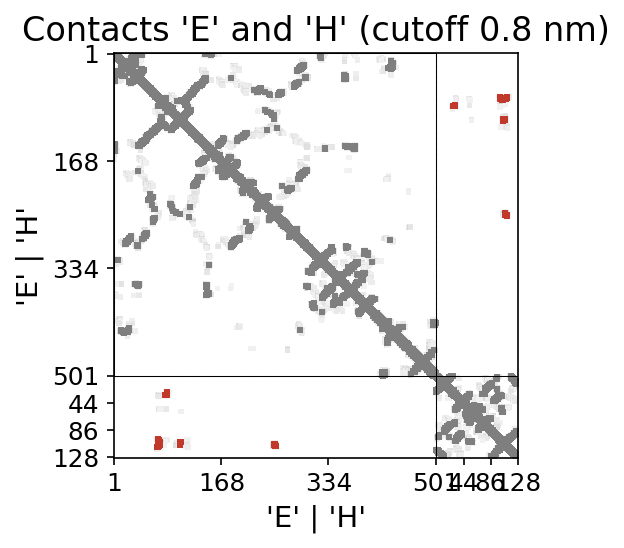

In [6]:
pdb_6mid.plot_contacts_two('E','H')




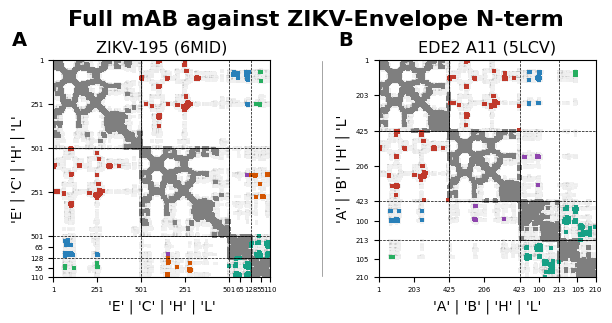

(<Figure size 700x350 with 2 Axes>,
 [<Axes: title={'center': 'ZIKV-195 (6MID)'}, xlabel="'E' | 'C' | 'H' | 'L'", ylabel="'E' | 'C' | 'H' | 'L'">,
  <Axes: title={'center': 'EDE2 A11 (5LCV)'}, xlabel="'A' | 'B' | 'H' | 'L'", ylabel="'A' | 'B' | 'H' | 'L'">])

In [7]:
mABs_Nterm = plot_grid_with_letters(plot_funcs=[plot_6mid, plot_5lcv], ncols=2, main_title="Full mAB against ZIKV-Envelope N-term")
mABs_Nterm

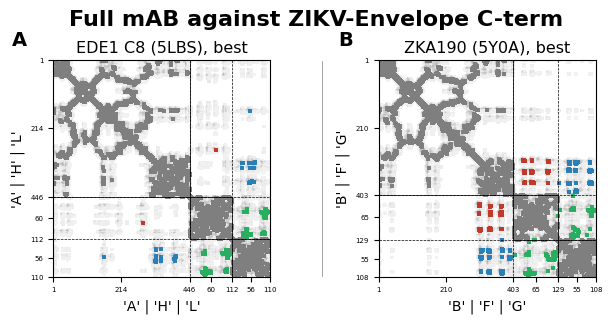

(<Figure size 700x350 with 2 Axes>,
 [<Axes: title={'center': 'EDE1 C8 (5LBS), best'}, xlabel="'A' | 'H' | 'L'", ylabel="'A' | 'H' | 'L'">,
  <Axes: title={'center': 'ZKA190 (5Y0A), best'}, xlabel="'B' | 'F' | 'G'", ylabel="'B' | 'F' | 'G'">])

In [8]:
mABs_Cterm = plot_grid_with_letters(plot_funcs=[plot_5lbs_A, plot_5y0a_B], ncols=2, main_title="Full mAB against ZIKV-Envelope C-term")
mABs_Cterm

## Antibody Sequence Analysis and Design

Ideally we could design two artificial constructs in tandem to target both regions on the dimer.

In [9]:
pdb_6mid.summary()

,chain_id,auth_chain_id,entity_id,description,external_ref,sequence_length,reference_length,mapped_residues,mapping_fraction
0,C,C,1,E protein,A0A142I5B9,501,3423,501,1.0
1,D,D,2,M protein,A0A142I5B9,75,3423,75,1.0
2,E,E,1,E protein,A0A142I5B9,501,3423,501,1.0
3,F,F,2,M protein,A0A142I5B9,75,3423,75,1.0
4,G,H,3,monoclonal antib...,NaN,127,128,127,1.0
5,H,L,4,monoclonal antib...,"6MID, A0A0B4J1U3",110,110,110,1.0
6,J,I,5,2-acetamido-2-de...,NaN,0,0,0,0.0
7,K,J,5,2-acetamido-2-de...,NaN,0,0,0,0.0


In [18]:
### <INTERFACES DICTIONARY>
import copy

# 1. Build the base interface dictionary
interface_dict = {}
for pdb_id, sync in zip(PDB_IDS, synced_list):
    palette = palettes[pdb_id]
    env_chains = [k for k, v in palette.items() if v in (envelope, envelope2)]
    ab_chains = [k for k, v in palette.items() if v in (heavy, light)]
    all_chains = list(palette.keys())
    
    for env_id in env_chains:
        for ab_id in ab_chains:
            sync_copy = copy.deepcopy(sync)
            for chain_id in all_chains:
                if chain_id not in (env_id, ab_id):
                    sync_copy.remove_chain(chain_id)
            interface_dict[(pdb_id, env_id, ab_id)] = sync_copy

### <\INTERFACES DICTIONARY>

In [20]:
### <SEQUENCE EXTRACTION>
interface_pairs_dict = {}
for (pdb_id, env_id, ab_id), sync_copy in interface_dict.items():
    pal = palettes[pdb_id]
    pair_key = f"{pdb_id}_{env_id}_{ab_id}"
    interface_pairs_dict[pair_key] = {}
    
    for c in (env_id, ab_id):
        col = pal.get(c)
        if col in (envelope, envelope2, heavy, light):
            seq, mask = sync_copy.get_sequence(c), sync_copy.get_contact_sequence(c)
            interface_pairs_dict[pair_key][c] = {
                'pdb_id': pdb_id,
                'env_chain': env_id,
                'ab_chain': ab_id,
                'chain': c,
                'seq': seq,
                'mask': mask,
                'masked': "".join('X' if b == '0' else ch for ch, b in zip(seq, mask)),
                'rev_masked': "".join('X' if b == '1' else ch for ch, b in zip(seq, mask))
            }
### <\SEQUENCE EXTRACTION>

In [24]:
print(interface_pairs_dict.keys())

dict_keys(['6MID_E_H', '6MID_E_L', '6MID_C_H', '6MID_C_L', '5LCV_A_H', '5LCV_A_L', '5LCV_B_H', '5LCV_B_L', '5LBS_A_H', '5LBS_A_L', '5LBS_A_I', '5LBS_A_M', '5LBS_B_H', '5LBS_B_L', '5LBS_B_I', '5LBS_B_M', '5Y0A_A_D', '5Y0A_A_E', '5Y0A_A_F', '5Y0A_A_G', '5Y0A_A_H', '5Y0A_A_L', '5Y0A_B_D', '5Y0A_B_E', '5Y0A_B_F', '5Y0A_B_G', '5Y0A_B_H', '5Y0A_B_L', '5Y0A_C_D', '5Y0A_C_E', '5Y0A_C_F', '5Y0A_C_G', '5Y0A_C_H', '5Y0A_C_L', '5KVG_E_H', '5KVG_E_L'])


In [27]:
## H and L from 6MID ---> 6MID_E_H, 6MID_E_L
## F and G from 5Y0A ---> 5Y0A_B_F, 5Y0A_B_G


In [43]:
import json

SEED=42
CHAIN_IDS = ("A", "B")
INTERNAL_LINKER = "GGGGSGGGGSGGGGS"
INTER_SCFV_LINKER = INTERNAL_LINKER + "SSGPGSS" + INTERNAL_LINKER
af_json_fp = EXPORT_DIR / "ZIKAbs_AF3_jobs.json"

ab1_heavy = interface_pairs_dict["6MID_E_H"]["H"]["seq"]
ab1_light = interface_pairs_dict["6MID_E_L"]["L"]["seq"]
ab2_heavy = interface_pairs_dict["5Y0A_B_F"]["F"]["seq"]
ab2_light = interface_pairs_dict["5Y0A_B_G"]["G"]["seq"]
envelope_seq = interface_pairs_dict["6MID_E_H"]["E"]["seq"]

ab1_scfv = ab1_light + INTERNAL_LINKER + ab1_heavy
ab2_scfv = ab2_heavy + INTERNAL_LINKER + ab2_light
tandem_scfv1_scfv2 = ab1_scfv + INTER_SCFV_LINKER + ab2_scfv

constructs = [
    ("scFv1", ab1_scfv),
    ("scFv2", ab2_scfv),
    ("tandem_scfv1_scfv2", tandem_scfv1_scfv2),
]

af_jobs = [
    {
        "name": f"envelope_x2_x_{name}",
        "modelSeeds": [str(SEED)],
        "sequences": [
            {"proteinChain": {"id": CHAIN_IDS[0], "sequence": envelope_seq, "count": 2}},
            {"proteinChain": {"id": CHAIN_IDS[1], "sequence": antibody_seq, "count": 1}},
        ],
    }
    for name, antibody_seq in constructs
]

af_json_fp.parent.mkdir(parents=True, exist_ok=True)
af_json_fp.write_text(json.dumps(af_jobs, indent=2))

3607

In [ ]:
#!/usr/bin/env python3
"""Build a tandem bispecific scFv sequence."""

###################################### construct_bispecific_scfv


ab1_heavy = interface_pairs_dict['6MID_E_H']['H']
ab1_light = interface_pairs_dict['6MID_E_L']['L']
ab2_heavy = interface_pairs_dict['5Y0A_B_F']['F']
ab2_light = interface_pairs_dict['5Y0A_B_G']['G']

def get_seq(chain):
    return chain['seq'] if isinstance(chain, dict) else chain

ab1_heavy = get_seq(ab1_heavy)
ab1_light = get_seq(ab1_light)
ab2_heavy = get_seq(ab2_heavy)
ab2_light = get_seq(ab2_light)

ab1_scfv = ab1_light + INTERNAL_LINKER + ab1_heavy
ab2_scfv = ab2_heavy + INTERNAL_LINKER + ab2_light
bispecific_scfv = ab1_scfv + INTER_SCFV_LINKER + ab2_scfv

print(f"ANTIBODY-1 scFv ({len(ab1_scfv)} aa):\n{ab1_scfv}")
print(f"ANTIBODY-2 scFv ({len(ab2_scfv)} aa):\n{ab2_scfv}")
print(f"BISPECIFIC scFv ({len(bispecific_scfv)} aa):\n{bispecific_scfv}")

In [48]:

af_results = EXPORT_DIR / 'AF3_results_bispecific_AB.cif'
af3 = SyncedStructure.from_Path(af_results)
af3.summary()

[PYTHON-INFO] 2026-10-18 13:34:14 | Loaded local structure tutorial-data/ZIKV/AF3_results_bispecific_AB.cif | execution time: 0.57s | max memory: 982.3 MB


,chain_id,auth_chain_id,entity_id,description,external_ref,sequence_length,reference_length,mapped_residues,mapping_fraction
0,A,A,1,None,None,501,0,0,0.0
1,B,B,2,None,None,501,0,0,0.0
2,C,C,3,None,None,541,0,0,0.0


In [57]:
PALETTE={"A":envelope, "B":envelope2, "C":scfv}

af3.jupy_viz(size=500, angles=(-17, 75, -33), colors=PALETTE)

[PYTHON-INFO] 2026-10-18 13:37:42 | Rendered view of AF3_results_bispecific_AB at angles (-17, 75, -33) | execution time: 0.70s | max memory: 982.3 MB
